# Exploring radius, depth and the finite model

Put a closed ball of radius $r$ around each site, and keep the locations covered by at least $k$ balls. This set is the **multicover** at radius $r$ and coverage depth $k$. It grows when we increase $r$ or decrease $k$, giving a filtration with two parameters, or a **bifiltration**.

We will start with two sites and watch their balls meet. Their finite cell model will let us compute the merging of components, then recover its map in a finite encoding. A square will show how a loop appears and fills, and a final comparison will explain why related constructions from eligible sites answer a different geometric question.

The examples use TamerOp and CairoMakie in the [notebook environment](../src/start/install.md). The saved figures need no running Julia process. `filtered_complex` retains the cells before homology and encoding, so its inspector can compute homology from their boundary matrices at a chosen parameter. The figures use coefficients in $\mathbb F_2$, the field with two elements; the later encoding example explicitly uses $\mathbb Q$. [Finite encodings](../finite_encodings.md) explains how that resulting module recovers spaces and maps at the original parameters.

## Two balls meet at a closed boundary

Take sites at $(0,0)$ and $(2,0)$. At radius $3/4$ their balls are disjoint, giving two connected components. At radius one the closed balls touch, and their union becomes connected. Degree zero homology should therefore change from dimension two to dimension one.

We will compute only at depth one by requesting `depth_range=(1,1)`. The construction must keep the cells made by cutting its model at that depth. These form a **terminal cap**, and in this example the cap contains the edge that joins the two components. The [depth window guide](../rhomboid_depth.md) shows why this edge would disappear if we merely deleted vertices at other depths.

The model has a depth coordinate as well as spatial coordinates. We draw its first two coordinates with `view_dims=(1,2)`; this projection affects the picture, while `depth_range` determines which depths are actually constructed.

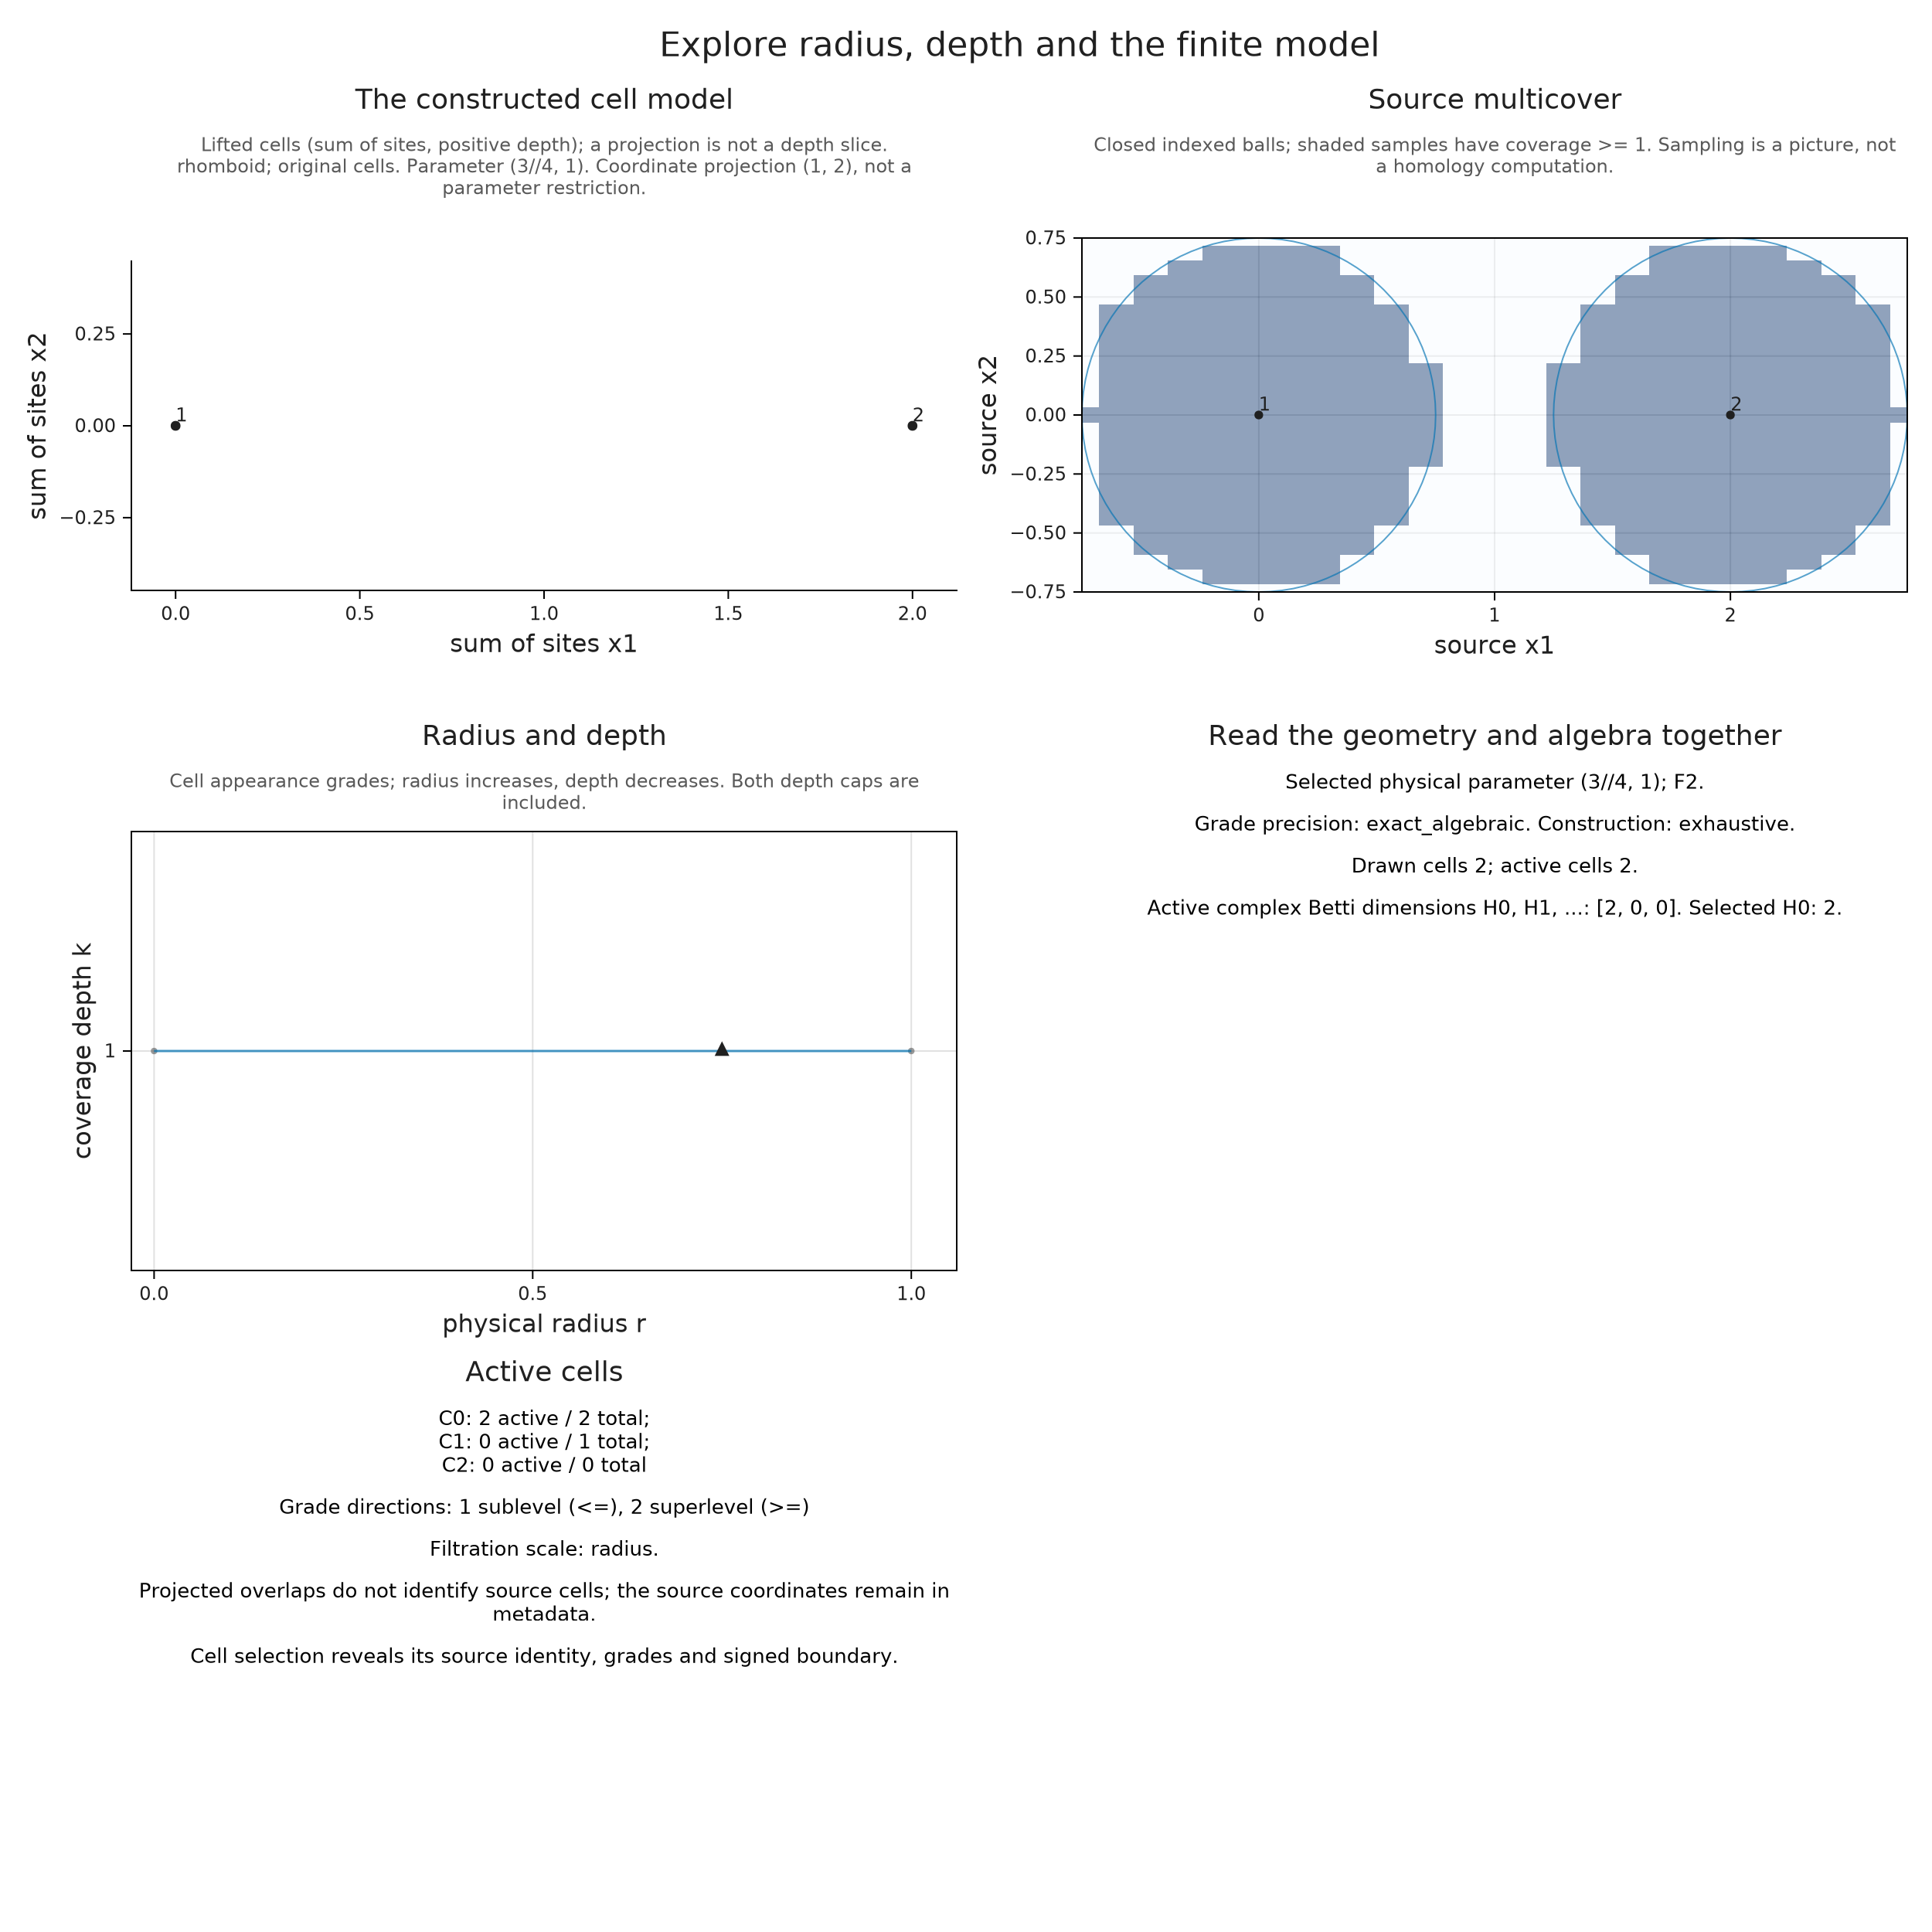

In [1]:
import TamerOp as OP
import CairoMakie
const V = OP.Visualization
const A = OP.Advanced

points = OP.PointCloud([0 0; 2 0])
filtration = OP.RhomboidFiltration(depth_range=(1,1))
cells = OP.filtered_complex(points, filtration)
before = A.visual_spec(cells; kind=:geometric_filtration,
    parameter=(3//4,1), view_dims=(1,2), labels=true)
@assert before.metadata.selected_betti == 2
OP.visualize(before)


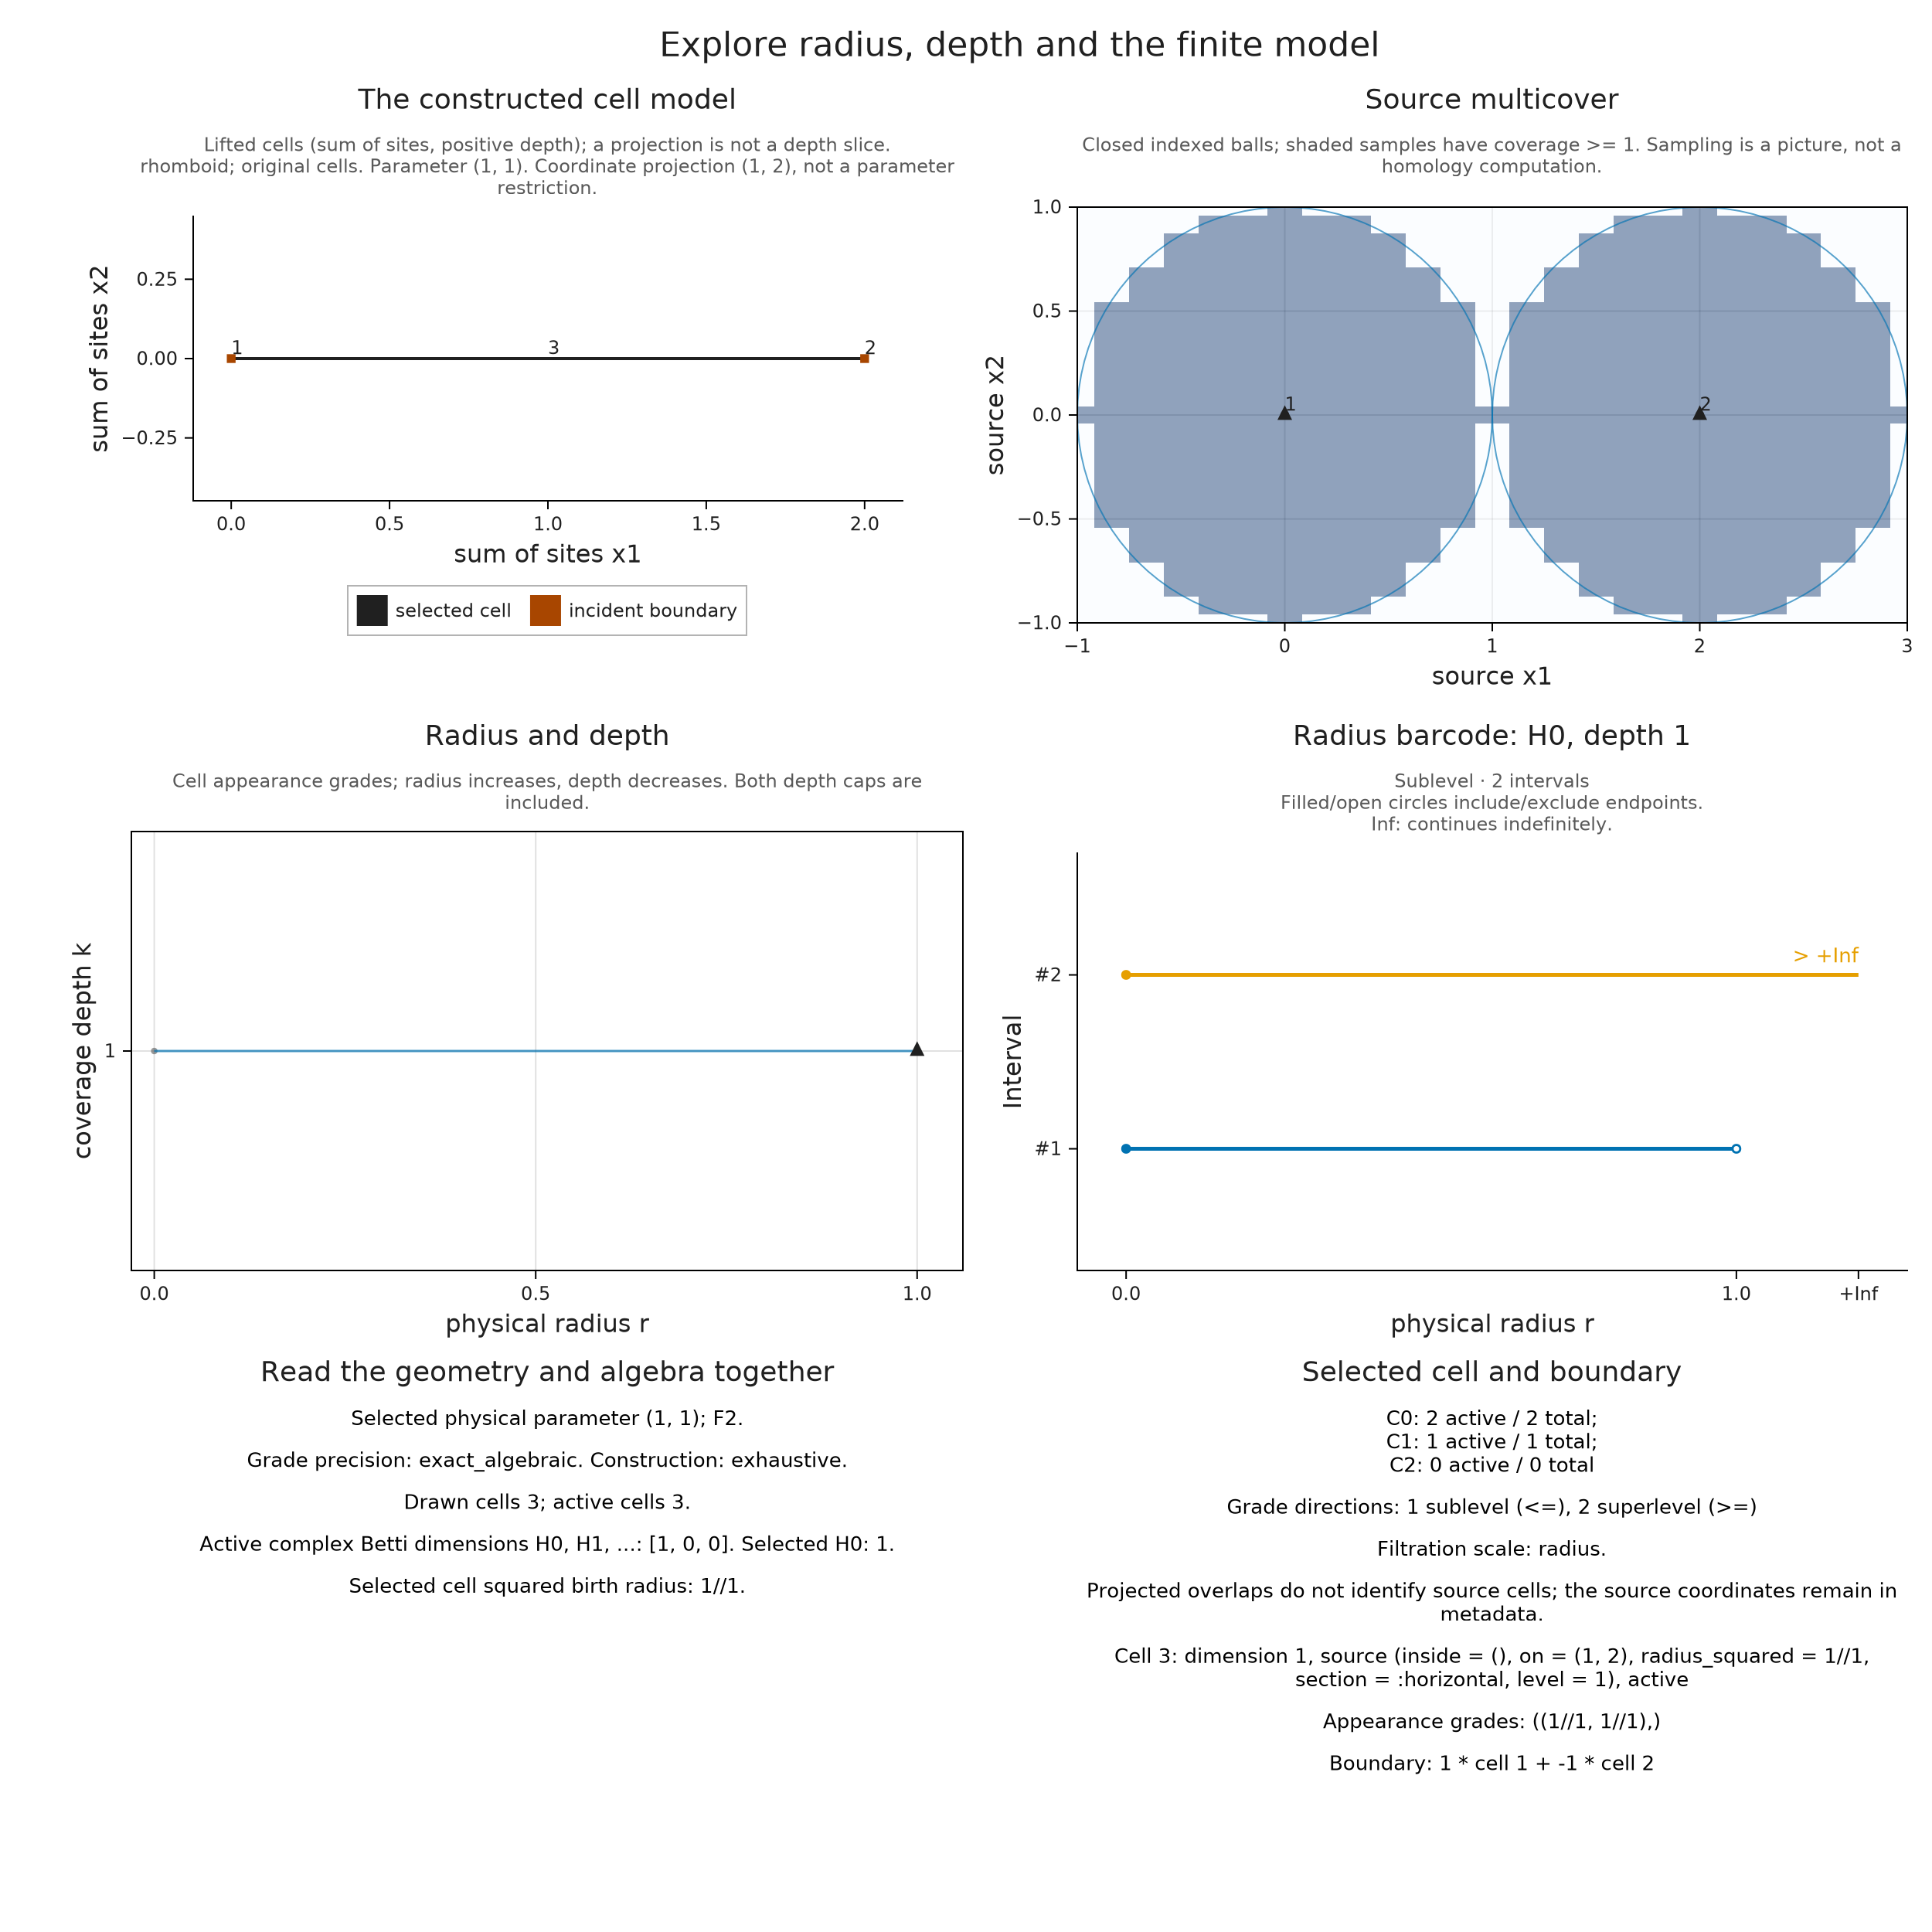

In [2]:
at_contact = A.visual_spec(cells; kind=:geometric_filtration,
    parameter=(1,1), view_dims=(1,2), cell=3, labels=true,
    invariant=:barcode)
@assert at_contact.metadata.selected_betti == 1
@assert A.cell_source(cells,3).radius_squared == 1
OP.visualize(at_contact)


At contact, the selected edge joins the two vertices and the degree zero dimension drops to one. The parameter panel records grades where cells appear. Some such events leave homology unchanged, so the panel need not agree event for event with the barcode. That barcode follows physical radius with depth held fixed at one.

The source panel samples points to draw the covered region. An isolated point of contact can fall between samples, so we can ask about its membership exactly. The midpoint $(1,0)$ belongs to both closed balls at radius one and to neither at a slightly smaller radius. The queries below convert their inputs before squaring the radius, preserving this equality.

In [3]:
contact = A.coverage_at(cells, (1,0); parameter=(1,1))
just_before = A.coverage_at(cells, (1,0); parameter=(1-big(1)//big(2)^60,1))
@assert contact.covered_sites == [1,2]
@assert !just_before.member
(contact=contact, squared_birth=A.cell_source(cells,3).radius_squared)


(contact = (count = 2, covered_sites = [1, 2], eligible_sites = [1, 2], contributing_sites = [1, 2], member = true, parameter = (1, 1), radius_squared = 1//1, family = :multicover), squared_birth = 1//1)

## Continue through the finite encoding

The pictures have helped us identify the cells responsible for the merge. Encoding their homology will give its linear map and an assignment from parameters to labels on a finite poset. Cells use the physical coordinates $(r,k)$; the encoding uses $(r,-k)$ so that enlarging the complex increases both coordinates.

We keep the same construction specification and ask for degree zero over $\mathbb Q$. Its dimensions still count components, and now the merge matrix has rational entries. The default axes retain the critical grades. If you supply custom axes, include every critical coordinate to preserve the original births: [floor placement on a coarser grid](../ingestion_options.md#grades-orientation-and-the-parameter-grid) can move them. The cell inspector continues to use their original grades.

In [4]:
encoded = OP.encode(points, filtration; degree=0, field=OP.CoreModules.QQField())
classifier = OP.encoding_map(encoded)
labels = [A.locate(classifier,p) for p in ([3//4,-1],[1,-1])]
dimensions = OP.dimensions(encoded)[labels]
merge_map = A.structure_map(OP.encoding_module(encoded); source=labels[1], target=labels[2])
@assert dimensions == [2,1]
@assert size(merge_map) == (1,2)
@assert OP.FieldLinAlg.rank(OP.CoreModules.QQField(),merge_map) == 1
(; dimensions, merge_map)


(dimensions = [2, 1], merge_map = Rational{BigInt}[1 1])

The classifier locates our two parameters on the finite base. The displayed matrix has two columns for the earlier components and one row for their connected union. Its rank is one because both component classes reach the same class. We can use the resulting spaces and maps in module algebra, or query another comparable pair of parameters. A barcode at one fixed depth only describes the restriction along that depth.

## Planar sites, lifted cells

For three sites that are not collinear, the native model can contain cells of dimension three. A vertex labelled by a subset $S$ has coordinates $(\sum_{i\in S}a_i,|S|)$: the sum of the site coordinates, followed by the number of sites. The final coordinate is the positive depth used in this drawing. We include depth zero to see the whole small model; requiring coverage by at least zero balls leaves all ambient space, which has one component.

The figure shows faces through dimension two, the **two dimensional skeleton**, of each higher cell. Homology still uses all constructed dimensions. By contrast, `max_dim` in the construction removes cells above the chosen dimension and can remove boundaries that would have filled a cycle.

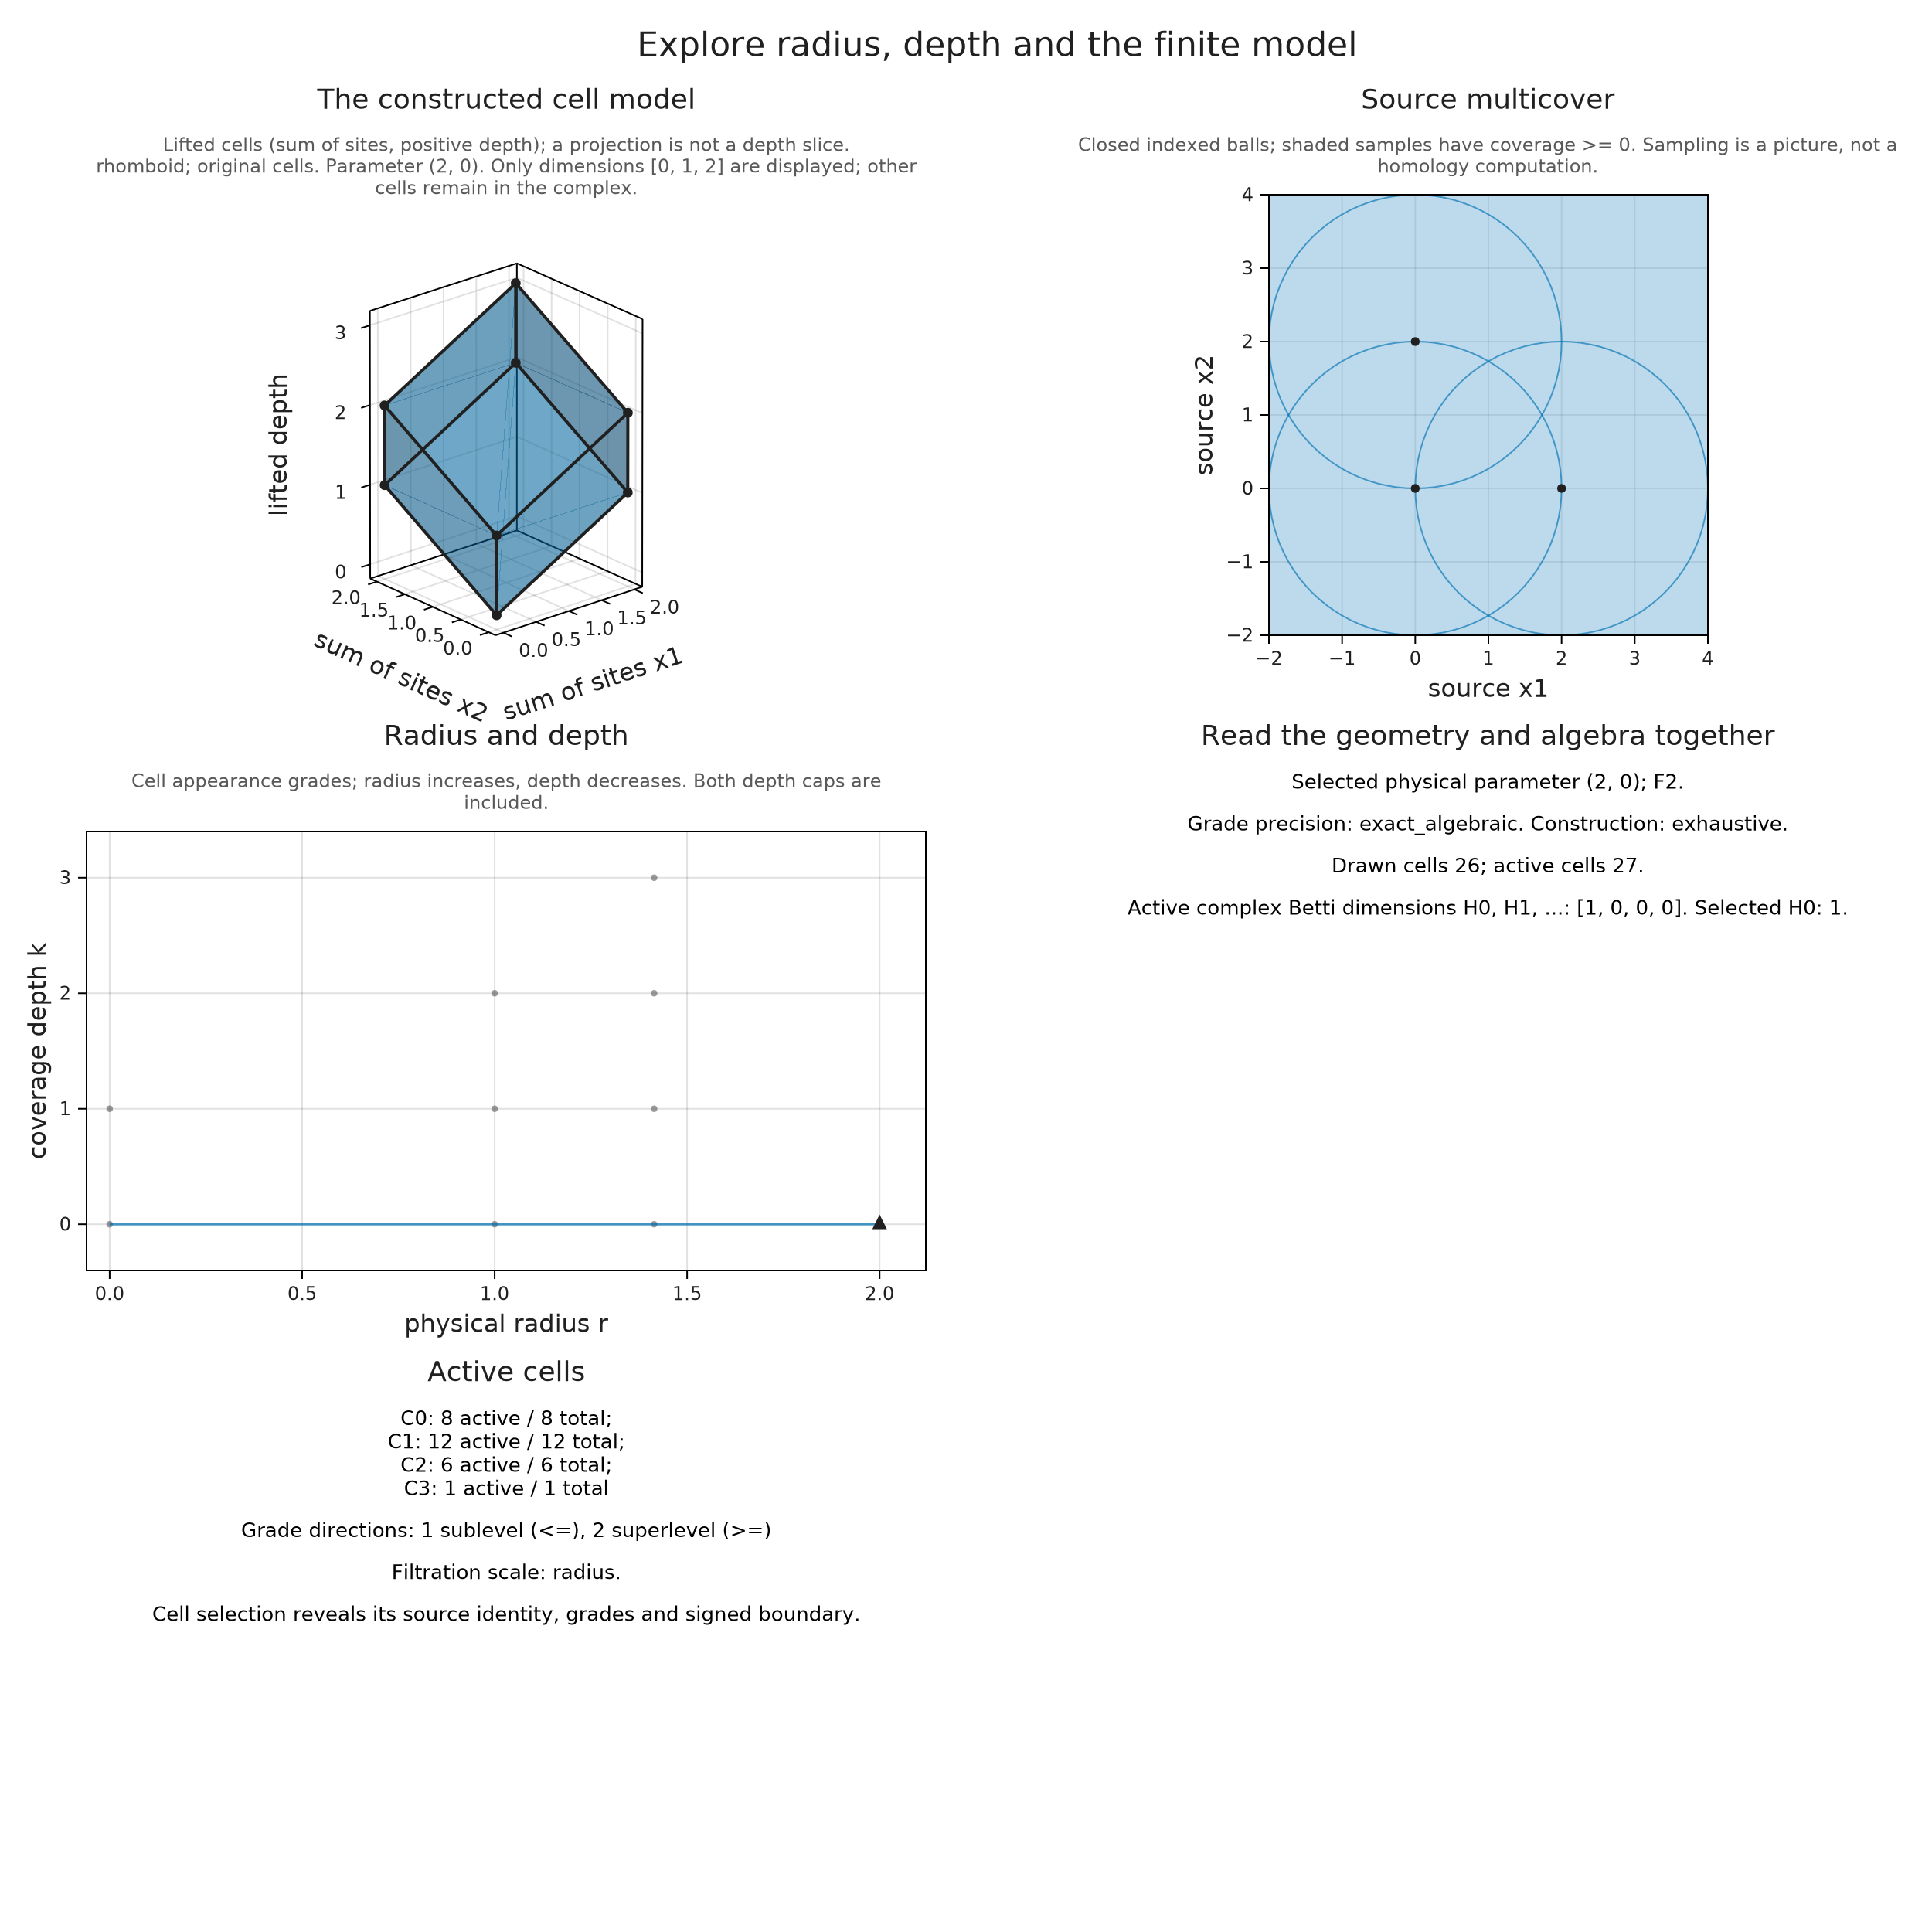

In [5]:
triangle = OP.PointCloud([0 0; 2 0; 0 2])
lifted = OP.filtered_complex(triangle, OP.RhomboidFiltration())
lifted_view = A.visual_spec(lifted; kind=:geometric_filtration, parameter=(2,0))
@assert lifted_view.metadata.skeleton
@assert lifted_view.metadata.selected_betti == 1
OP.visualize(lifted_view)


A projection can place different vertices at the same position without identifying them in the complex. To select an actual horizontal section at integer depth $k$, construct `depth_range=(k,k)`. The [depth window guide](../rhomboid_depth.md) explains that section and its cap; [the construction account](../implementation/rhomboid_construction.md) explains how labels, radii and signed boundaries define the model.

## A square needs a different cell model

The four corners of a square lie on one circle. The native rhomboid construction assumes general position and rejects this configuration, so we choose `backend=:subdivision_cech` explicitly. It keeps the site positions and builds a different complex. A vertex represents a labelled subset of sites, and a simplex represents a **flag**, a strictly increasing chain of these subsets.

For the drawing, vertices are placed at the mean positions of their subsets. Opposite pairs in the square have the same mean, so distinct vertices can overlap. Their labels still distinguish them in the computation. Subset and flag enumeration can grow exponentially, which is why this construction requires a finite cell budget.

At depth one, the four balls first meet their neighbours at radius one. Their union then has one loop, which survives until radius $\sqrt2$ covers the center. The following two views should show a degree one class on the interval $[1,\sqrt2)$, with the death endpoint excluded.

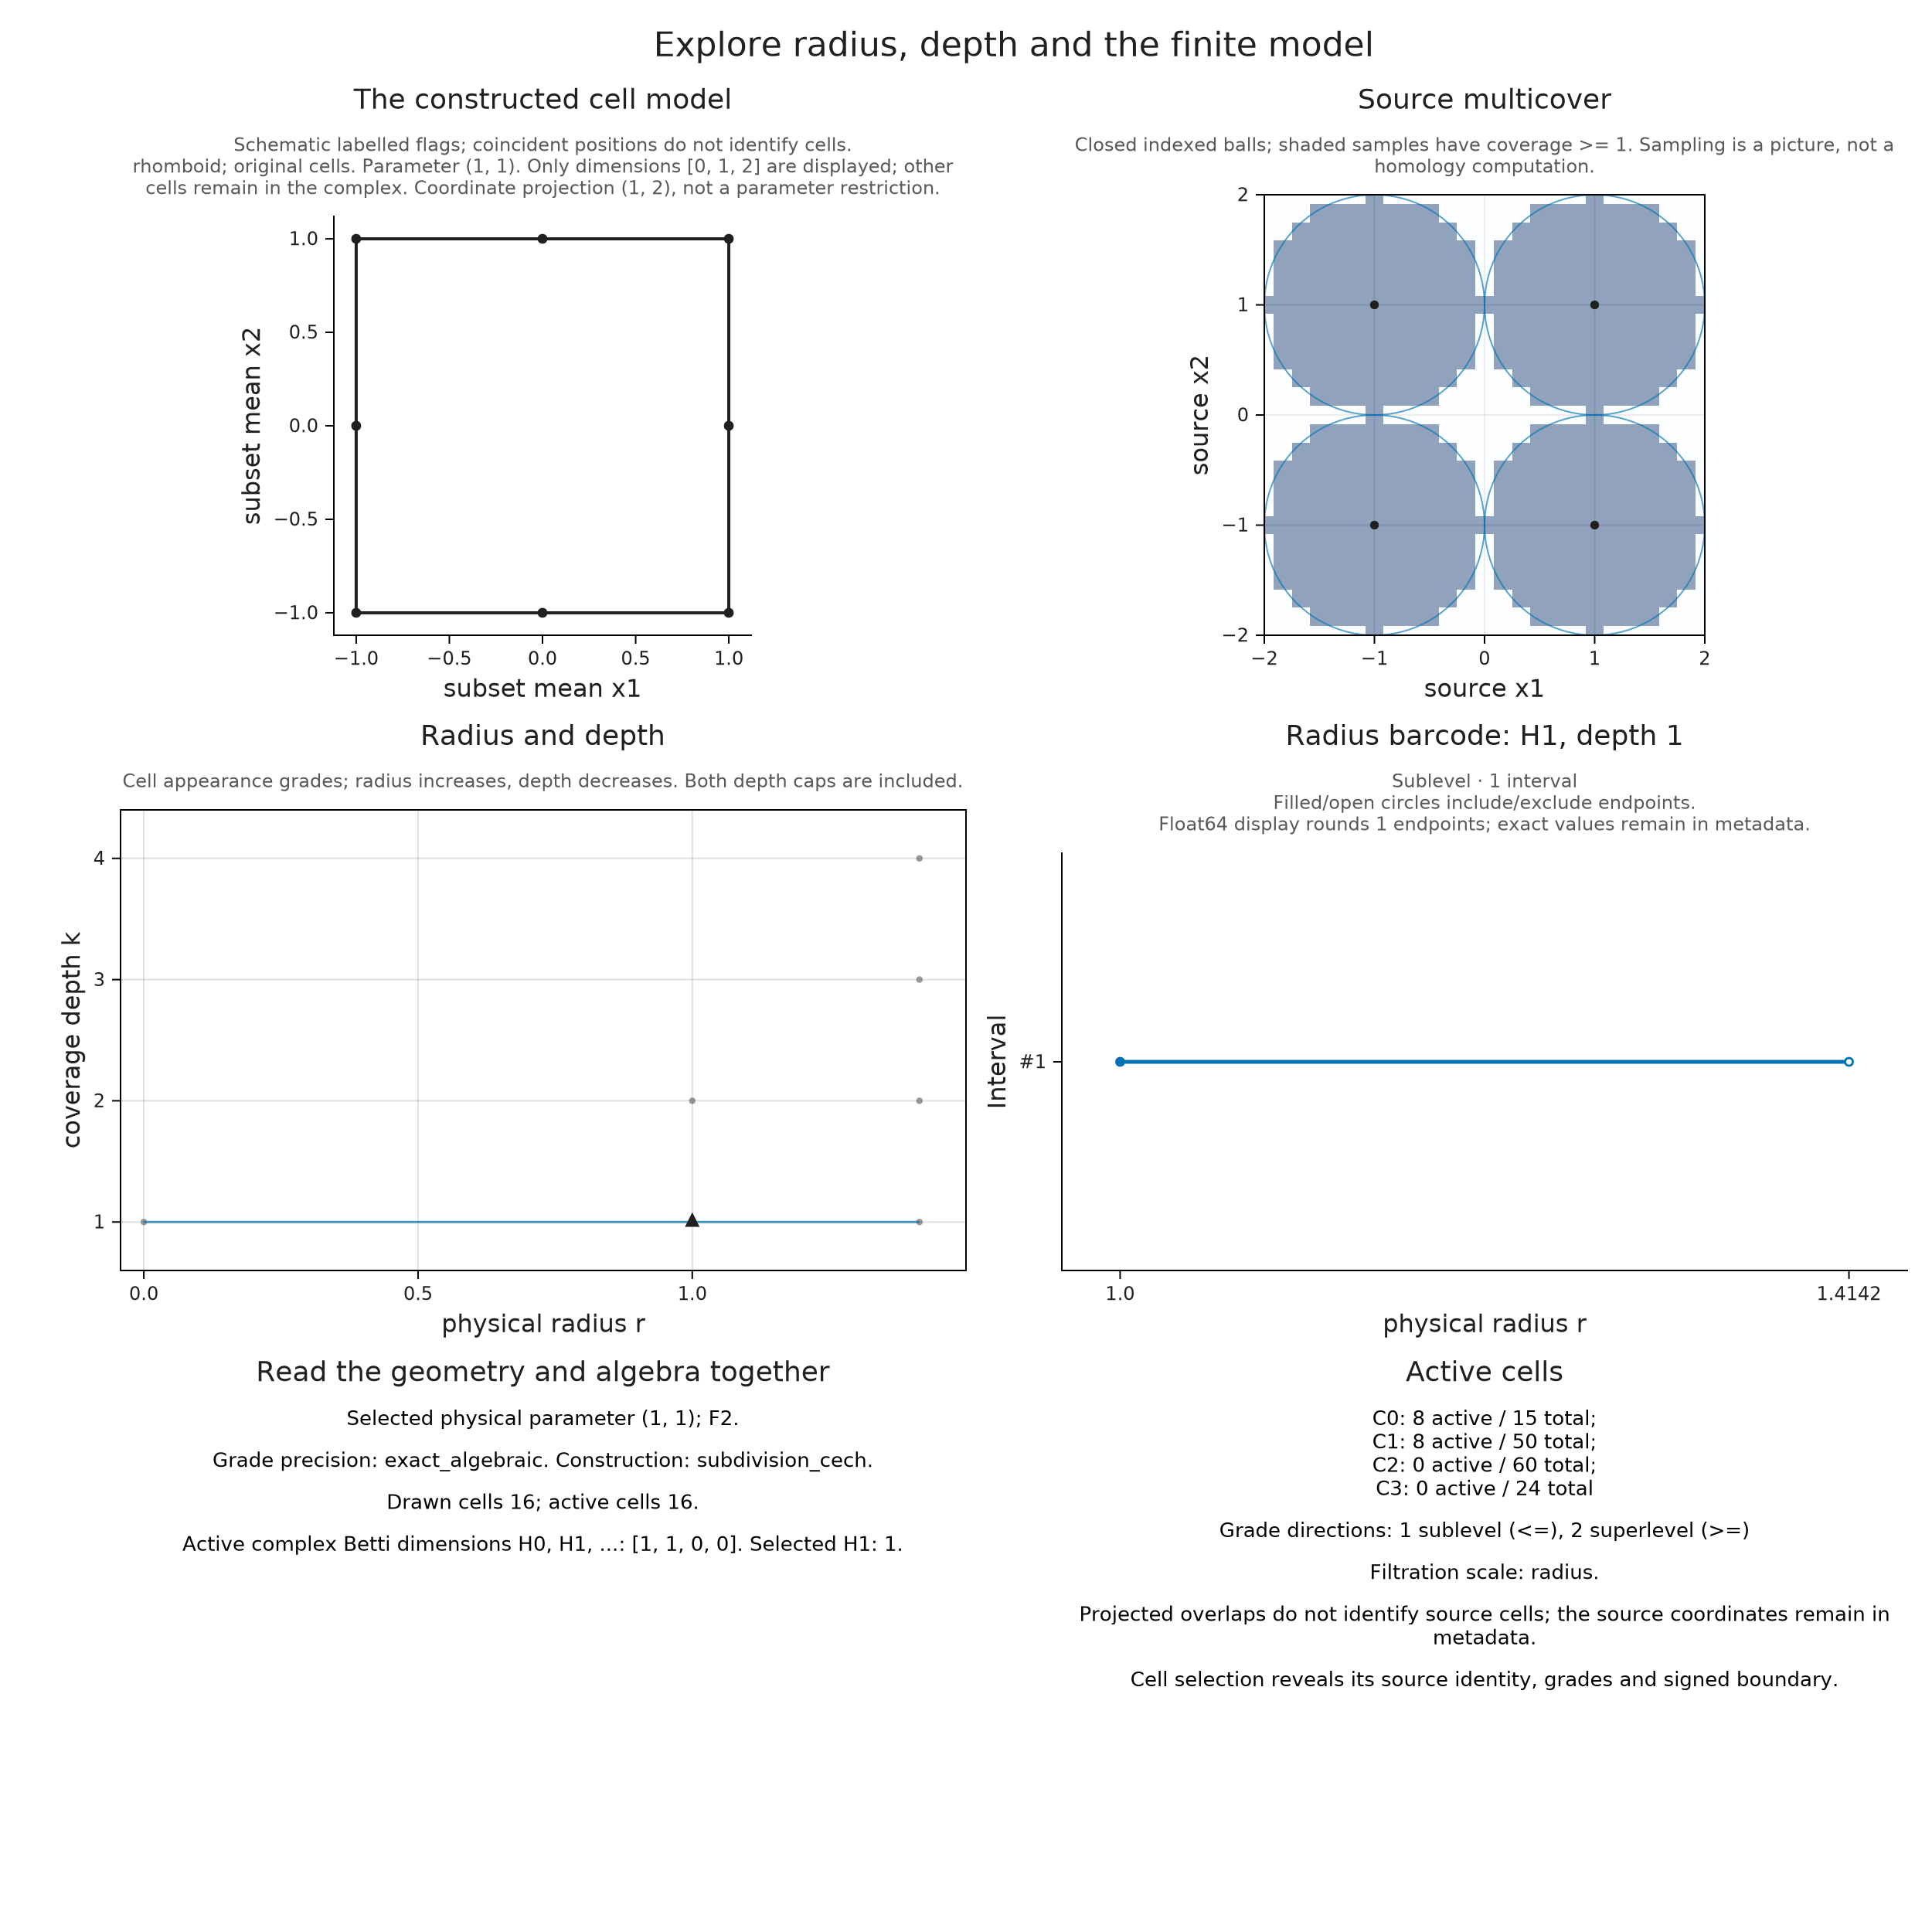

In [6]:
square = OP.PointCloud([-1 -1; 1 -1; 1 1; -1 1])
budget = OP.ConstructionOptions(budget=OP.ConstructionBudget(max_simplices=20_000))
square_filtration = OP.RhomboidFiltration(backend=:subdivision_cech,
    depth_range=(1,4), construction=budget)
flags = OP.filtered_complex(square, square_filtration)
loop_view = A.visual_spec(flags; kind=:geometric_filtration, parameter=(1,1),
    degree=1, invariant=:barcode, view_dims=(1,2), max_cells=100)
@assert loop_view.metadata.selected_betti == 1
OP.visualize(loop_view)


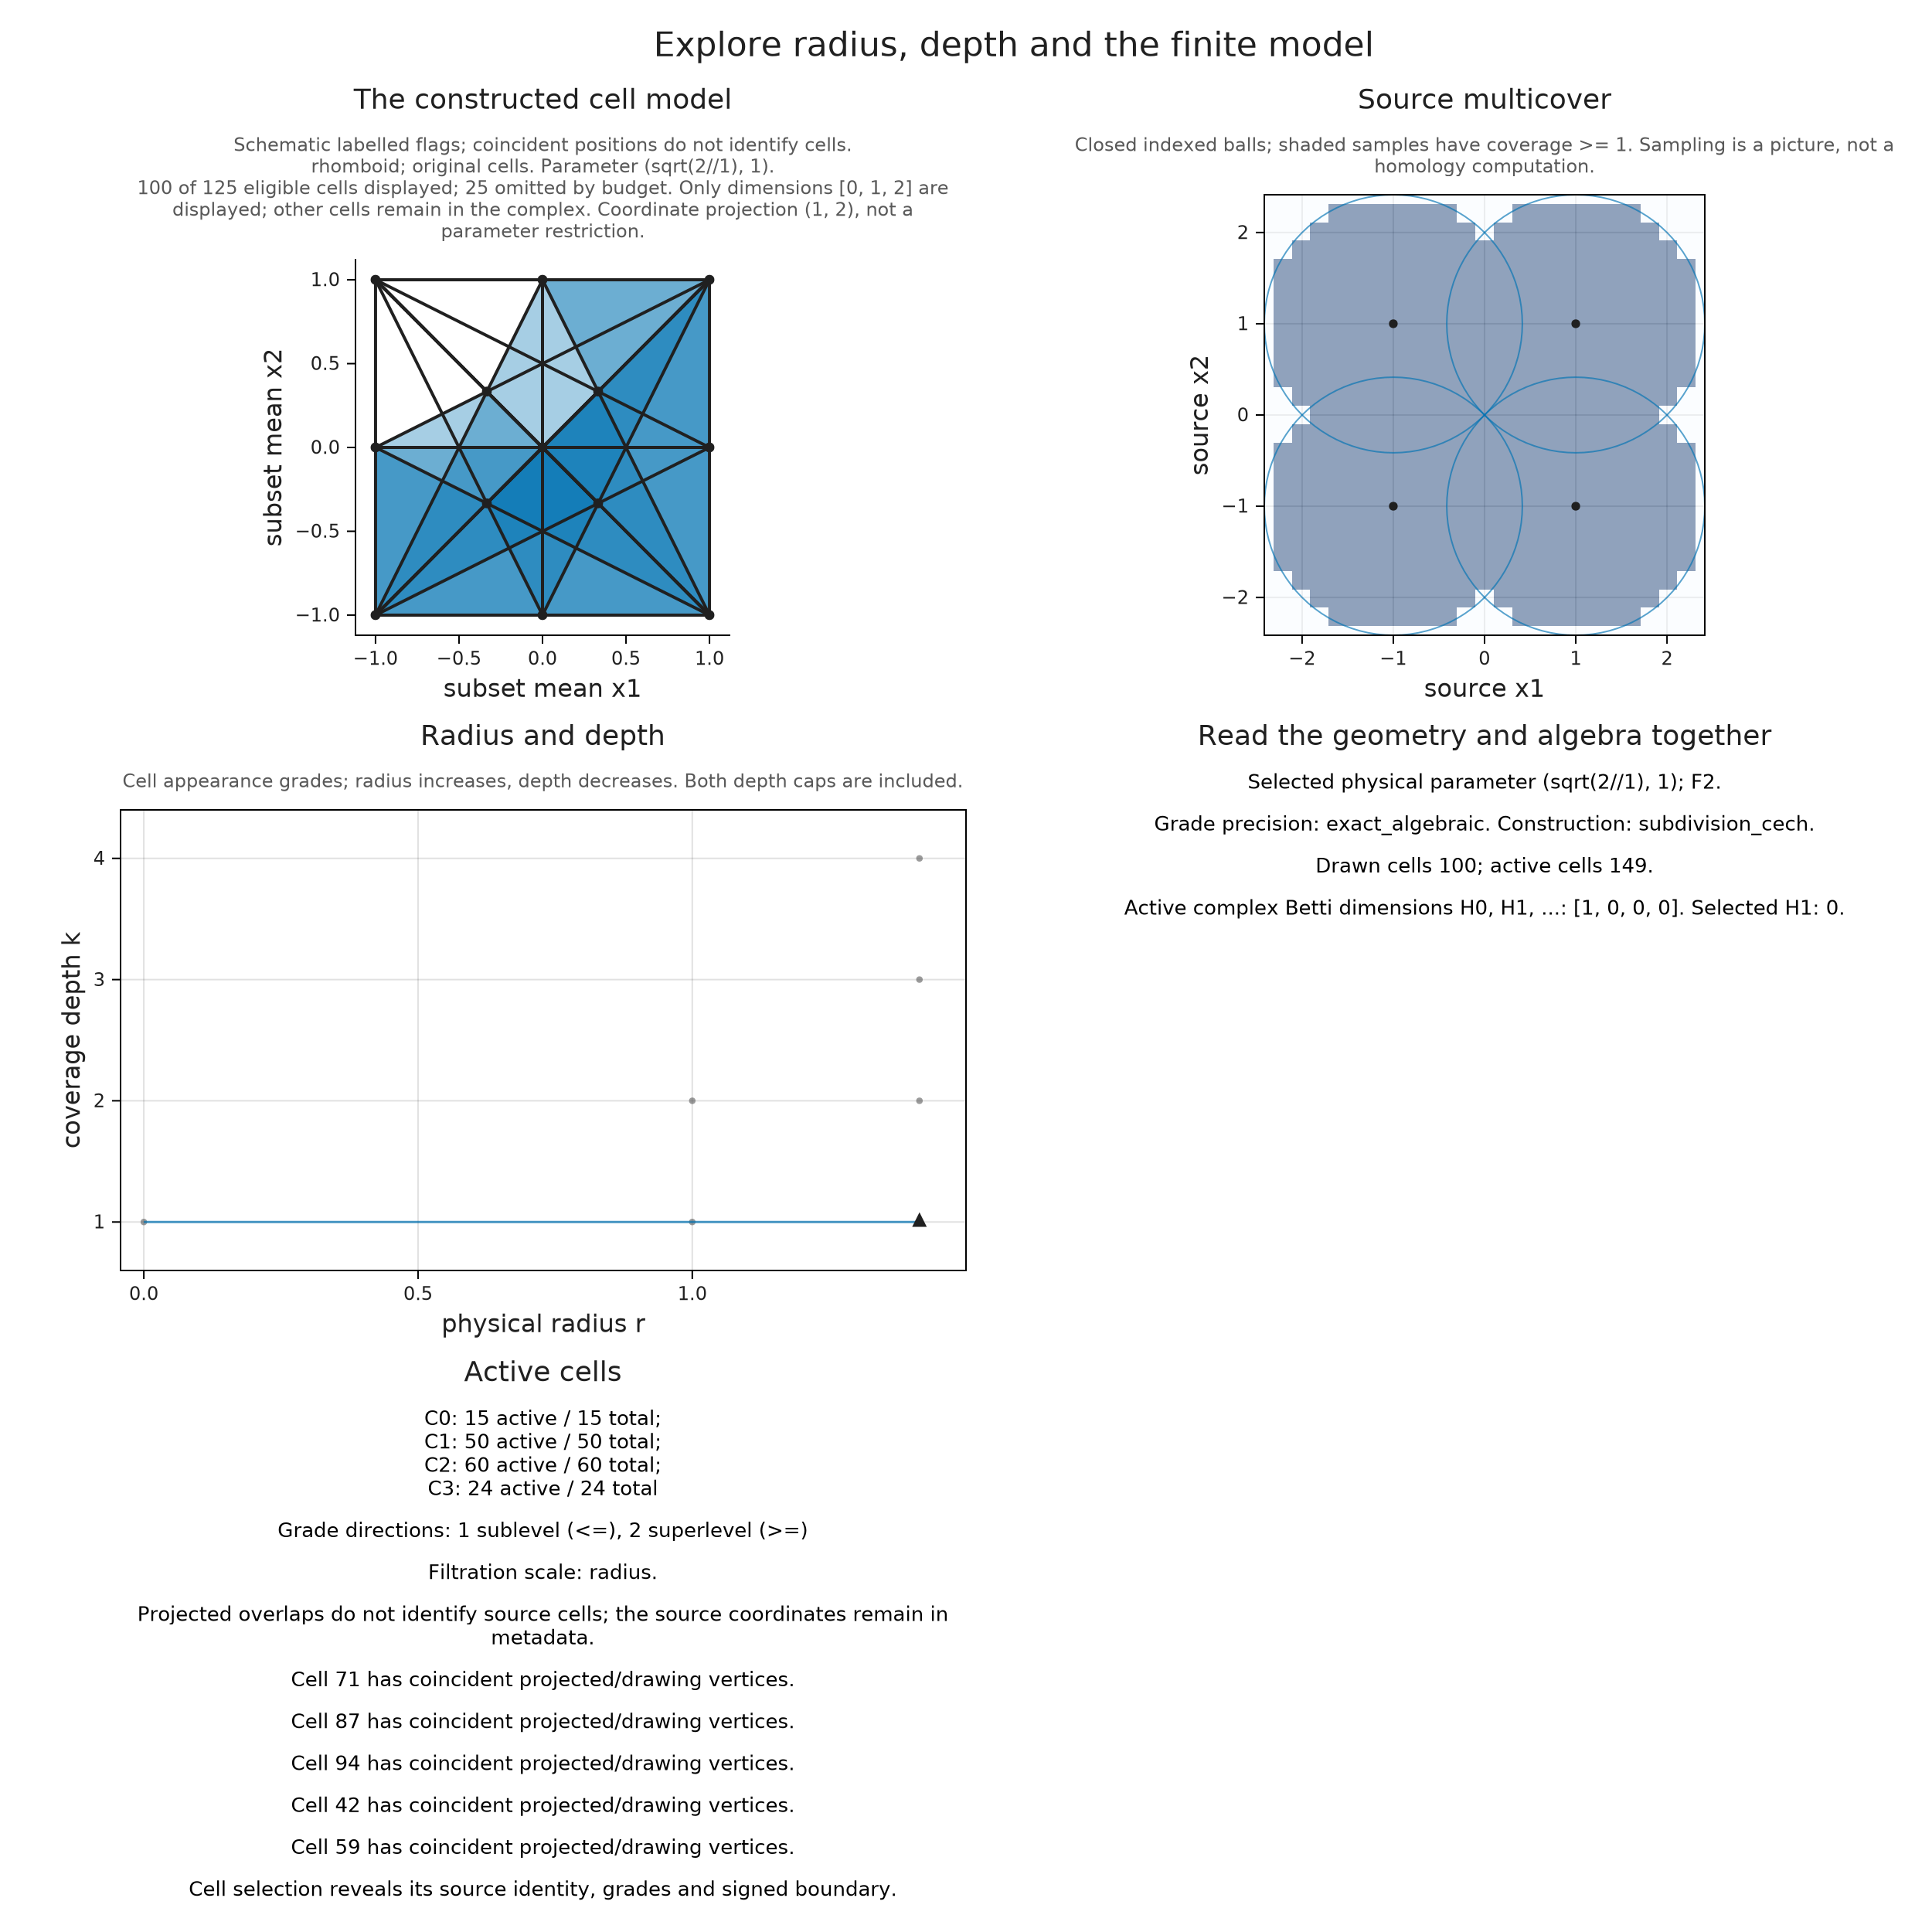

In [7]:
sqrt_two = sqrt(OP.AlgebraicReal(2))
filled_view = A.visual_spec(flags; kind=:geometric_filtration,
    parameter=(sqrt_two,1), degree=1, view_dims=(1,2), max_cells=100)
@assert filled_view.metadata.selected_betti == 0
radius_complex = A.radius_slice(flags; depth=1)
diagram = OP.persistence_diagram(radius_complex)
@assert OP.OrdinaryPersistence.finite_intervals(diagram; dim=1) == [(1,sqrt_two)]
OP.visualize(filled_view)


## Repeated labels count more than once

Two sites at the same coordinate still stand for two indexed balls. At their shared center, both balls contribute to the coverage depth, even at radius zero. The flag construction keeps those two labels; deleting a repeated site would change the question. In the picture below, the repeated sites at $(0,0)$ already give one component at depth two, while the isolated site at $(2,0)$ does not meet that coverage requirement.

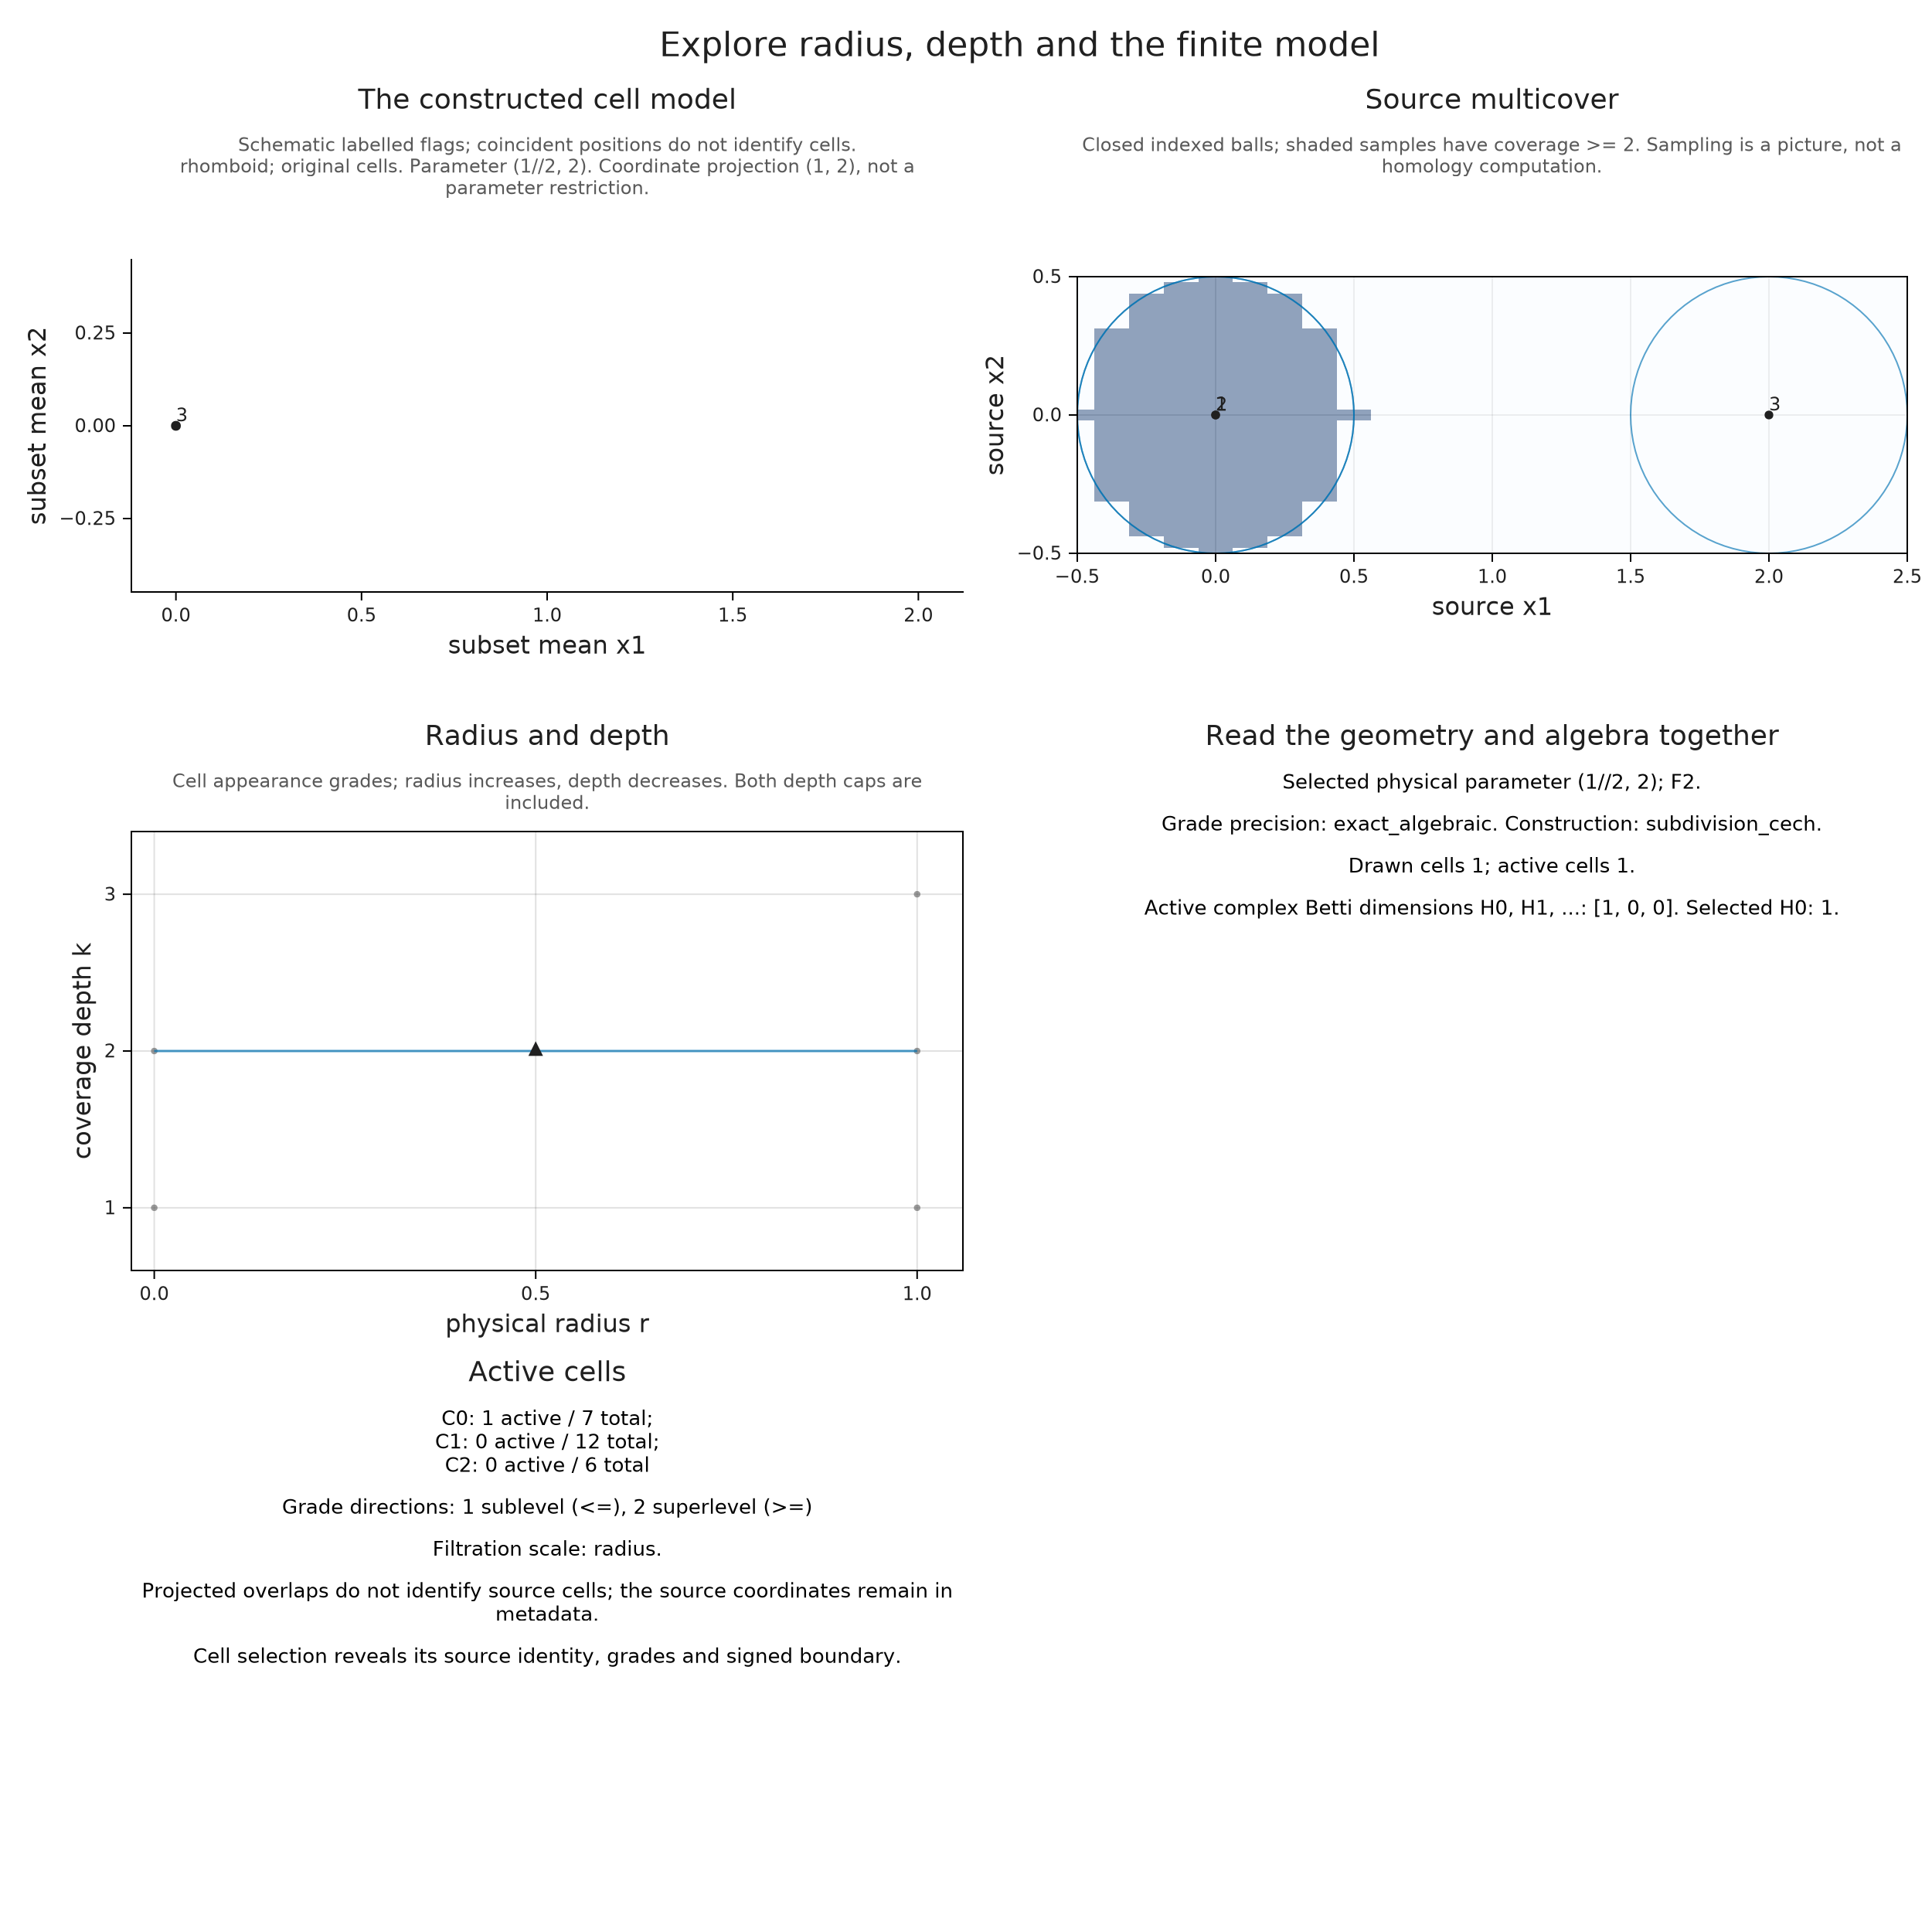

In [8]:
repeated = OP.PointCloud([0 0; 0 0; 2 0])
repeated_cells = OP.filtered_complex(repeated, OP.RhomboidFiltration(
    backend=:subdivision_cech, depth_range=(1,3), construction=budget))
@assert A.coverage_at(repeated_cells, (0,0); parameter=(0,2)).covered_sites == [1,2]
repeated_view = A.visual_spec(repeated_cells; kind=:geometric_filtration,
    parameter=(1//2,2), view_dims=(1,2), labels=true)
@assert repeated_view.metadata.selected_betti == 1
OP.visualize(repeated_view)


## Core constructions ask another geometric question

A core construction first decides which sites are eligible. Count the site itself as its first nearest neighbour, and let its core distance at depth $k$ be the distance to its $k$th nearest site. With the default scale, it is eligible when this distance is at most $r$; a general `beta` multiplies the core distance before that comparison. The construction retains these eligibility thresholds as vertex grades. Core–Čech takes the union of balls at eligible sites. Core–Delaunay first intersects each of these balls with the site's Voronoi cell, the region nearer to it than to any other site in the full cloud. These numerical geometric constructions can give a different region from multicover, where we count balls covering each location.

At $(r,k)=(2,2)$ below, the sites $(0,0)$ and $(2,0)$ each have core distance 2 and are eligible. The site $(0,3)$ has core distance 3 and remains excluded. Here the indexed sites and the spatial coordinates of the two cell models agree, so we can overlay them for a geometric comparison. The invariant in the figure belongs to the primary `core` object. Agreement in the picture, or even in a Betti number, would not establish an isomorphism of persistence modules or an approximation bound.

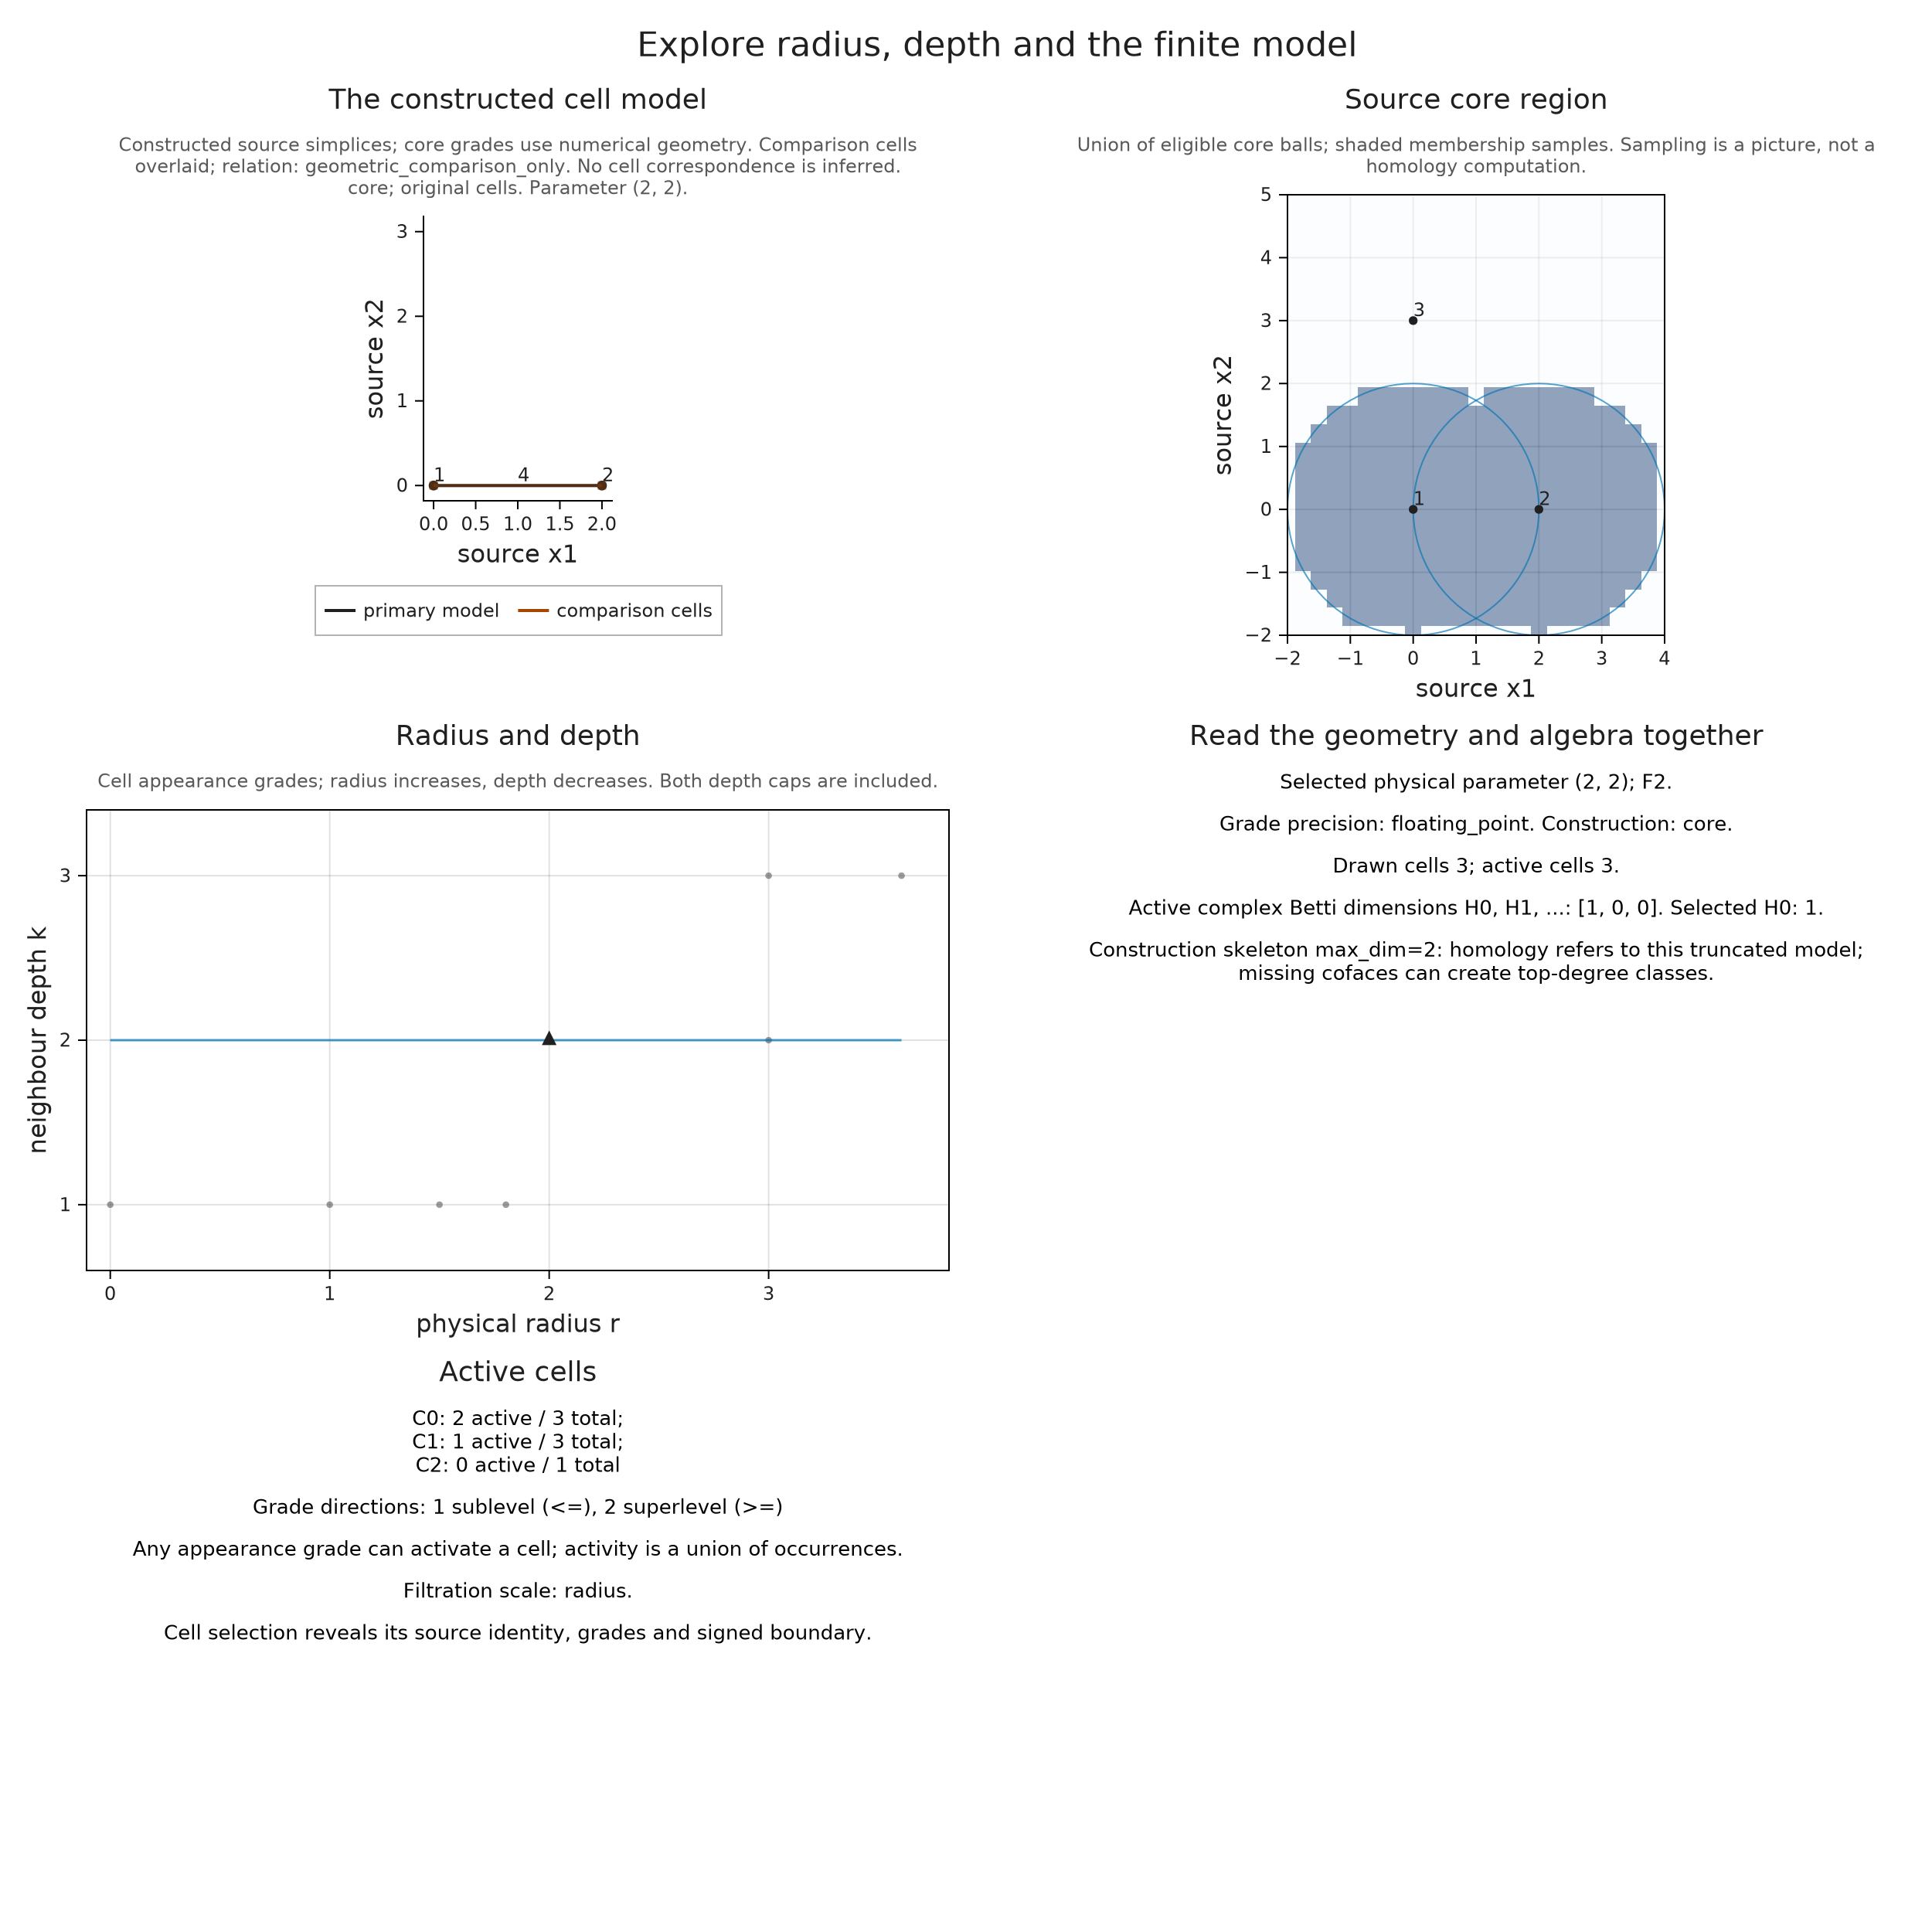

In [9]:
core_points = OP.PointCloud([0 0; 2 0; 0 3])
core = OP.filtered_complex(core_points, OP.CoreFiltration(k_values=[1,2,3]))
core_delaunay = OP.filtered_complex(core_points, OP.CoreDelaunayFiltration(k_values=[1,2,3]))
core_view = A.visual_spec(core; kind=:geometric_filtration, parameter=(2,2),
    compare=core_delaunay, labels=true)
@assert core_view.metadata.comparison.relation == :geometric_comparison_only
OP.visualize(core_view)


## Keep an inspectable state

An inspection session lets us return to a chosen parameter, cell and set of display coordinates. Here we move the two-site example to contact, retain its snapshot and close the session. Closing releases the live inputs; the snapshot remains available for viewing and export.

In [10]:
session = OP.inspection_session(cells; kind=:geometric_filtration,
    parameter=(3//4,1), view_dims=(1,2))
A.select_inspection!(session; parameter=(1,1), cell=3)
snapshot = A.inspection_snapshot(session)
@assert snapshot.metadata.selected_betti == 1
A.close_inspection!(session)
OP.describe(snapshot)


(kind = :visualization_spec, visual_kind = :geometric_filtration, title = "Explore radius, depth and the finite model", subtitle = "", nlayers = 0, npanels = 5, layer_types = (), axes = (xlabel = "x", ylabel = "y", xlimits = nothing, ylimits = nothing, zlabel = "z", zlimits = nothing, aspect = :auto, xticks = nothing, yticks = nothing), metadata = (options = (parameter = (1, 1), cell = 3, dimensions = [0, 1, 2], activity = :active, boundary = true, view_dims = (1, 2), max_cells = 10000, labels = false, max_labels = 50, alpha = 0.35, field_axis = nothing), parameter = (1, 1), cell = 3, active = Bool[1, 1, 1], active_counts = [2, 1, 0], drawn_counts = [2, 1, 0], total_counts = [2, 1, 0], eligible_count = 3, omitted_count = 0, displayed_indices = [3, 1, 2], selected = (index = 3, cell_id = 1, dimension = 1, active = true, grades = ((1//1, 1//1),), source = (inside = (), on = (1, 2), radius_squared = 1//1, section = :horizontal, level = 1), geometry = Tuple{Rational{BigInt}, Rational{BigIn

To explore live controls, create a fresh session, load WGLMakie and call `OP.visualize(session; backend=:wglmakie)` with Julia running. The radius slider moves continuously within a bounded range, while the depth slider moves between integers in the construction window. At radius 1 the two closed balls meet. **Next event** selects that stored value exactly; a pointer position that looks close to contact can fall on either side, so the exact parameter field is useful for boundary questions.

The source picture, active cell counts and invariant are updated together. If a request is invalid or exceeds an algebra budget, the preceding snapshot remains available. A saved static figure contains one selected state. The [live inspection guide](live_inspection.ipynb) explains the shared controls and connection requirements, and the [geometric inspection reference](../src/reference/visualization.md#geometric-constructions-and-multicover) gives the precise options.

For a larger model, `invariant=:none` lets us inspect geometry without computing homology. `max_cells` limits the drawing; `max_algebra_cells` and `max_matrix_entries` separately limit the work requested for homology. Drawing a few cells still leaves the full constructed complex behind a barcode request.

## Choosing a native backend and a window

Native rhomboid constructions accept a nonempty cloud with integer, rational or finite floating coordinates. Floating inputs are interpreted as their exact binary rational values; irrational algebraic source coordinates are unsupported. Geometric decisions and squared radii use exact arithmetic, while physical birth radii can be algebraic square roots.

The inclusive window `depth_range=(lo,hi)` must lie in `0:npoints`. Depth zero represents contractible ambient space; a positive depth can instead have an empty multicover at small radii. Omitting the window gives the full unsliced native construction. Specifying one allows the constructor to omit irrelevant cells, while keeping the cap at `hi` that was needed in our two-site example.

`backend=:exhaustive` enumerates possible sphere supports and works in any affine dimension. `:incremental` discovers cells across depth levels using exact weighted Delaunay constructions, currently in affine dimensions zero through three. The affine dimension is the dimension of the smallest affine subspace containing the sites. Embedding such a cloud in a larger ambient space leaves its original Euclidean metric in use. Both native routes require general position in the geometry they compute; incremental enumeration includes prerequisite levels below `lo`, where degeneracy can prevent that route.

`:auto` chooses incremental enumeration for affine dimension two, at least 32 sites and an explicit window ending at depth two. Other requests use exhaustive enumeration. The executed choice is recorded in provenance. Neither route perturbs the sites or silently switches to the flag construction. For the algorithm behind these choices, see [discovery across depth levels](../implementation/rhomboid_construction.md#discover-cells-across-depth-levels).

## Reusing exact geometry

When we inspect the same cloud repeatedly, one `SessionCache` can retain its exact geometry between calls. Native requests share geometry when coordinate contents and shape, requested backend and depth window agree. Radius cutoffs, output dimensions, coefficient fields, axes and output stages can vary because their results are built from the same retained geometry.

The subdivision–Čech construction instead reuses subset minimum-ball radii for the same coordinates and lower depth bound; its upper depth bound affects the emitted grades. The two constructions have separate cache entries. Equal coordinate contents can reuse an entry, while changed coordinates require a new one. Returned complexes own their grades and boundaries, so editing a result leaves the cached geometry unchanged.

`cache=:auto` creates a cache for that call. Keep an explicit session for reuse across calls, as below, or use `cache=nothing` to disable it. A long session retains each distinct geometry until cleared or discarded, so using a fresh cache for a new batch of clouds helps limit retained memory. Construction budgets still apply to each request, including reuse, but do not bound the aggregate memory of all session entries. Avoid modifying a cloud while another task reads it; the [construction account](../implementation/rhomboid_construction.md#reuse-and-where-the-work-grows) explains concurrent requests and storage ownership.

In [11]:
cache = OP.SessionCache()
first_cells = OP.filtered_complex(points, filtration; cache)
second_cells = OP.filtered_complex(points, filtration; cache)
@assert A.cell_geometry(first_cells,3) == A.cell_geometry(second_cells,3)
OP.describe(second_cells)


(kind = :filtered_complex, cell_counts = [2, 1, 0], parameter_dim = 2, orientation = (1, -1), ambient_dim = 3, construction = (requested = :rhomboid, effective = :rhomboid, grade_scale = :radius, source_mapping = :inside_on_partitions, periodic = (), domain = nothing, lifting_maps = nothing, substitution = :none, projection = :none, filtration_parameters = (depth_range = (1, 1), backend = :auto, construction = (sparsify = :none, collapse = :none, output_stage = :encoding_result, budget = (max_simplices = nothing, max_edges = nothing, memory_budget_bytes = nothing))), sparsify = :none, collapse = :none, geometric = (sites = Rational{BigInt}[0 0; 2 0], family = :multicover, representation = :lifted_rhomboid, backend = :exhaustive, axes = (AlgebraicReal[0//1, 1//1], AlgebraicReal[-1//1]), radius_cutoff = nothing, depth_window = (1, 1), grade_precision = :exact_algebraic, max_dim = nothing), ambient_dim = 3, model = :original), representatives = :not_computed)

## Output size and interpretation

By default, `max_dim=nothing` keeps the complete chosen model. A dimension cutoff constructs its skeleton; computing degree $h$ homology generally needs cells through dimension $h+1$ because their boundaries can kill classes in degree $h$. The flag construction can have much higher dimension than a native rhomboid model on a comparable cloud.

A `radius` cutoff includes its endpoint. Custom encoding axes must stay within that radius and the oriented depth window; they can floor-snap births as explained earlier. Provenance records this change and any explicit quantization. The encoding may extend constantly beyond its last grid coordinate, but that extension does not answer the geometric multicover question outside the constructed window. Coefficient choices are recorded separately from the exact geometry.

Native `stage=:graded_complex` and module stages retain cellular boundaries. `stage=:simplex_tree` requests a compatible subdivision, which may contain many more simplices; the flag construction is already simplicial. Before a larger computation, use `estimate_ingestion`, inspect the graded complex and choose construction budgets. The estimate can omit savings from radius exclusions or shared cells when finding them would require doing the construction.

Continue with [spaces and maps](../spaces_and_maps.md) to query the finite encoding and use it in module algebra. For the construction mechanism itself, read [exact rhomboid construction](../implementation/rhomboid_construction.md).